# **Customer Segmentation:** 
## **Who are my customers and much are they willing to pay?**
  



  

In [1]:
import math
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

### **Initial Situation: the DATA**

In [2]:
# Import:
data = pd.read_csv("Mall_Customers.csv")

# Drop ID:
data = data.drop(labels="CustomerID", axis=1)

data

,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
...,...,...,...,...
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74
198,Male,32,137,18


Changing `Genre` to `Gender`.

In [3]:
data = data.rename(columns={"Genre": "Gender", 
                     "Age": "Age", 
                     "Annual Income ($k)": "Annual Income ($k)", 
                     "Spending Score (1-100)": "Spending Score (1-100)"})

data

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
...,...,...,...,...
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74
198,Male,32,137,18


### **Preprocessing**
#### **Investigating data types and distribution**

In [4]:
data.describe(include="all")

,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200,200.000000,200.000000,200.000000
unique,2,NaN,NaN,NaN
top,Female,NaN,NaN,NaN
freq,112,NaN,NaN,NaN
mean,NaN,38.850000,60.560000,50.200000
std,NaN,13.969007,26.264721,25.823522
min,NaN,18.000000,15.000000,1.000000
25%,NaN,28.750000,41.500000,34.750000
50%,NaN,36.000000,61.500000,50.000000
75%,NaN,49.000000,78.000000,73.000000


Count is equal in all over all features, indicating no missing values.

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Annual Income (k$)'}>],
       [<Axes: title={'center': 'Spending Score (1-100)'}>, <Axes: >]],
      dtype=object)

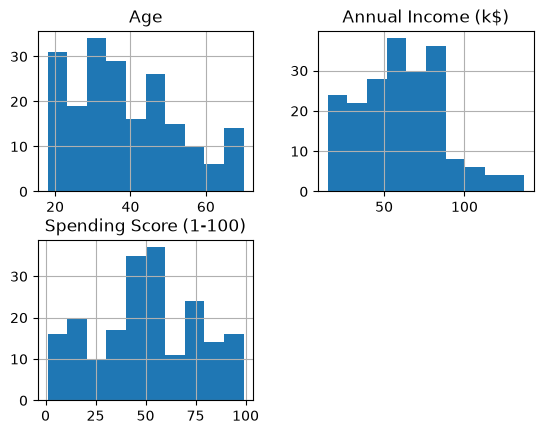

In [5]:
data.hist()

Relatively equal distribution in all numerical features.

<Axes: >

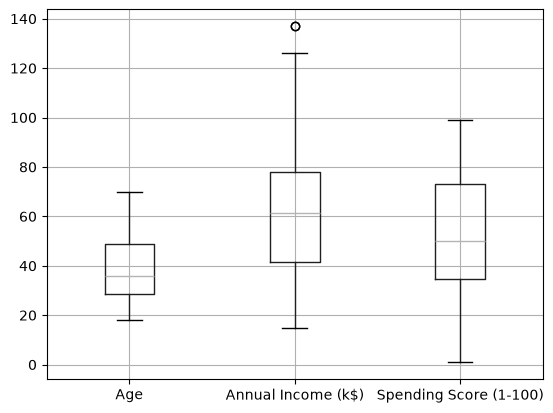

In [6]:
data.boxplot()

Few outliers in `Anual Income`. Investigating further.

In [7]:
q1: float = data["Annual Income (k$)"].quantile(0.25)  # First quartile
q3: float = data["Annual Income (k$)"].quantile(0.75)  # Third quartile
iqr: float = q3 - q1
print(f"Interquartile range: {iqr}")

upper_outliers: pd.Series = data["Annual Income (k$)"] > q3 + iqr * 1.5
print("\nUpper outliers:")
print(data[upper_outliers == True])

Interquartile range: 36.5

Upper outliers:
    Gender  Age  Annual Income (k$)  Spending Score (1-100)
198   Male   32                 137                      18
199   Male   30                 137                      83


Outliers seem neither representative nor decisive. Outliers will be dropped.

In [8]:
if (198 in data.index
    and 199 in data.index):
    data: pd.DataFrame = data.drop([198, 199], axis=0)

print("Outliers dropped:")
data.tail()

Outliers dropped:


,Gender,Age,Annual Income (k$),Spending Score (1-100)
193,Female,38,113,91
194,Female,47,120,16
195,Female,35,120,79
196,Female,45,126,28
197,Male,32,126,74


### **Converting data to all numeric values**

In [9]:
# Using OneHotEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer(
    [
        ("Gender transformed", OneHotEncoder(categories="auto", dtype=int, sparse_output=False), ["Gender"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
    )
transformer.set_output(transform="pandas")

num_data: pd.DataFrame = transformer.fit_transform(data)

print("Transformed data:")
num_data

Transformed data:


,Gender_Female,Gender_Male,Age,Annual Income (k$),Spending Score (1-100)
0,0,1,19,15,39
1,0,1,21,15,81
2,1,0,20,16,6
3,1,0,23,16,77
4,1,0,31,17,40
...,...,...,...,...,...
193,1,0,38,113,91
194,1,0,47,120,16
195,1,0,35,120,79
196,1,0,45,126,28


### **Analysis**
#### **Analysing correlation between data**
##### **Correlation matrix**

<Axes: >

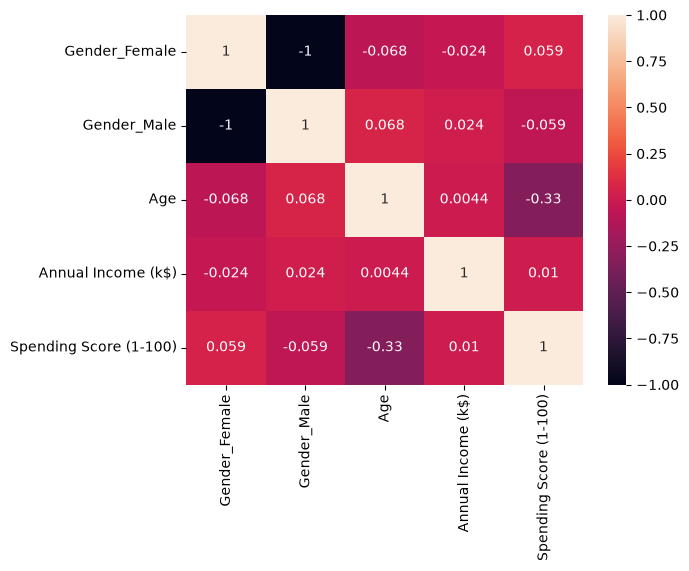

In [10]:
correlation_matrix = num_data.corr()
sns.heatmap(data=correlation_matrix, annot=True)

##### **Scatter plots**

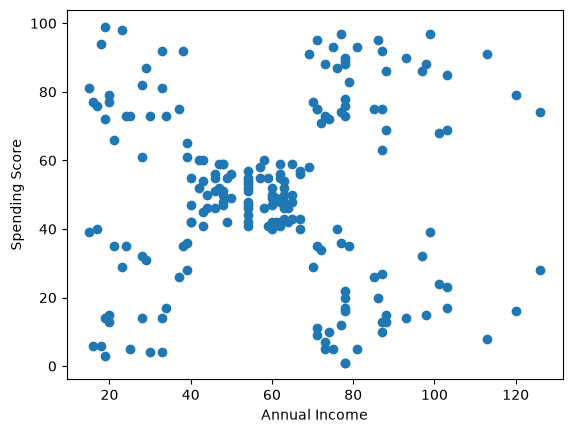

In [11]:
# Annual income and spending score
fig, ax = plt.subplots()

ax.scatter(x=data["Annual Income (k$)"],
           y=data["Spending Score (1-100)"])
ax.set_xlabel("Annual Income")
ax.set_ylabel("Spending Score")

plt.show()

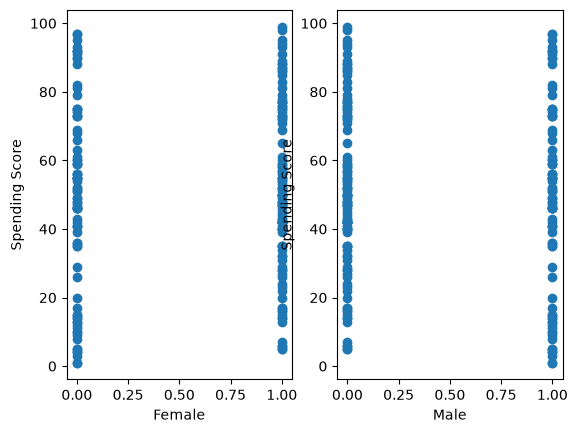

In [12]:
# Gender and spending score
fig, axs = plt.subplots(1, 2)
ax1, ax2 = axs

ax1.scatter(x=num_data["Gender_Female"],
            y=data["Spending Score (1-100)"])
ax1.set_xlabel("Female")
ax1.set_ylabel("Spending Score")

ax2.scatter(x=num_data["Gender_Male"],
            y=data["Spending Score (1-100)"])
ax2.set_xlabel("Male")
ax2.set_ylabel("Spending Score")

plt.show()

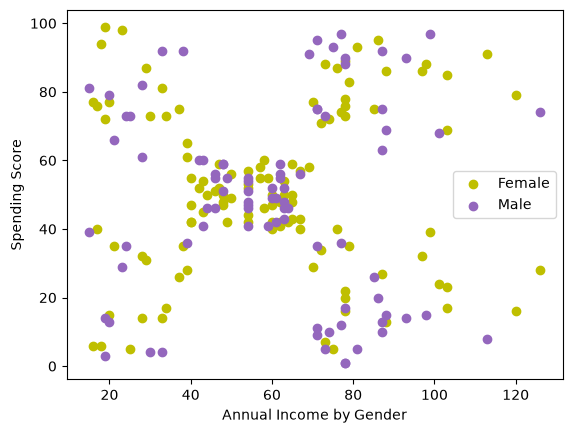

In [13]:
# Annual income and spending score by gender
fig, ax = plt.subplots()

female_sp = ax.scatter(x=data["Annual Income (k$)"].loc[data["Gender"] == "Female"],
                       y=data["Spending Score (1-100)"].loc[data["Gender"] == "Female"],
                       label="Female",
                       c="y")
male_sp = ax.scatter(x=data["Annual Income (k$)"].loc[data["Gender"] == "Male"],
                     y=data["Spending Score (1-100)"].loc[data["Gender"] == "Male"],
                     label="Male",
                     c="C4")
ax.set_xlabel("Annual Income by Gender")
ax.set_ylabel("Spending Score")
ax.legend(handles=[female_sp, male_sp])

plt.show()

`Gender` distribution is balanced and has no predictory value.

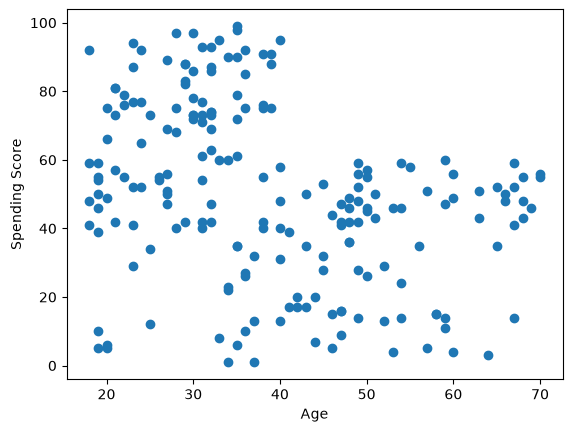

In [14]:
# Age and spending score
fig, ax = plt.subplots()

ax.scatter(x=data["Age"],
           y=data["Spending Score (1-100)"])
ax.set_xlabel("Age")
ax.set_ylabel("Spending Score")

plt.show()

`Age` shows tendency towards negative correlation. 

##### **Creating subset for analysis**

In [15]:
income_and_score: pd.DataFrame = data.drop(["Age", "Gender"], axis=1)
income_and_score

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
...,...,...
193,113,91
194,120,16
195,120,79
196,126,28


#### **Clustering data**

In [16]:
from sklearn.cluster import KMeans

clusterer = KMeans(
    n_clusters=5,
    init="k-means++",
    n_init="auto",
    algorithm="lloyd"
)

clustered = clusterer.fit(X=income_and_score)

centers: np.array = clustered.cluster_centers_
labels: np.array = clustered.labels_

income_and_score["Cluster_Label"] = labels

income_and_score

,Annual Income (k$),Spending Score (1-100),Cluster_Label
0,15,39,2
1,15,81,0
2,16,6,2
3,16,77,0
4,17,40,2
...,...,...,...
193,113,91,3
194,120,16,1
195,120,79,3
196,126,28,1


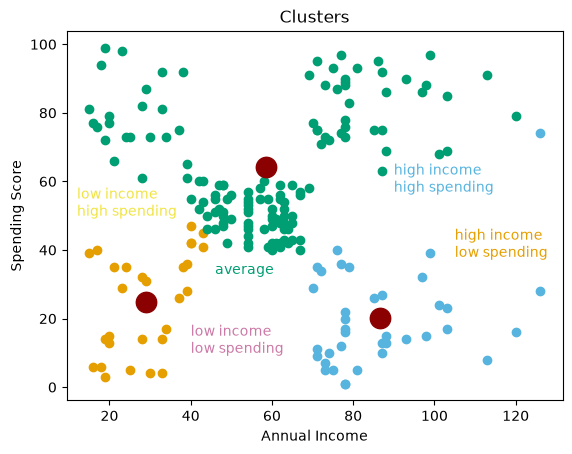

In [29]:
fig, ax = plt.subplots()
ax.set_xlabel("Annual Income")
ax.set_ylabel("Spending Score")
ax.set_title("Clusters")

colors: np.array = np.array([(230, 159, 0),   # Orange
                             (86, 180, 223),  # Light blue
                             (0, 158, 115),   # Green
                             (240, 228, 66),  # Yellow
                             (204, 121, 167)  # Pink
                             ]) / 255.0       # Colour blindness friendly

for i in range(len(income_and_score)):
    ax.scatter(x=income_and_score["Annual Income (k$)"].iloc[i],
               y=income_and_score["Spending Score (1-100)"].iloc[i],
               color=colors[income_and_score["Cluster_Label"].iloc[i]],
               label=f"Cluster {income_and_score["Cluster_Label"].iloc[i]}")

centroids = ax.scatter(x=centers[0:, 0],
                       y=centers[0:, 1],
                       c="DarkRed",
                       s=plt.rcParams['lines.markersize']**3,
                       label="Centroids")

ax.text(x=12, y=50, s="low income\nhigh spending", c=(0.9411, 0.8941, 0.2588))
ax.text(x=46, y=33, s="average", c=(0, 0.6196, 0.4509))
ax.text(x=40, y=10, s="low income\nlow spending", c=(0.8, 0.4745, 0.6549))
ax.text(x=90, y=57, s="high income\nhigh spending", c=(0.3372, 0.7058, 0.8745))
ax.text(x=105, y=38, s="high income\nlow spending", c=(0.9019, 0.6235, 0))

plt.show()

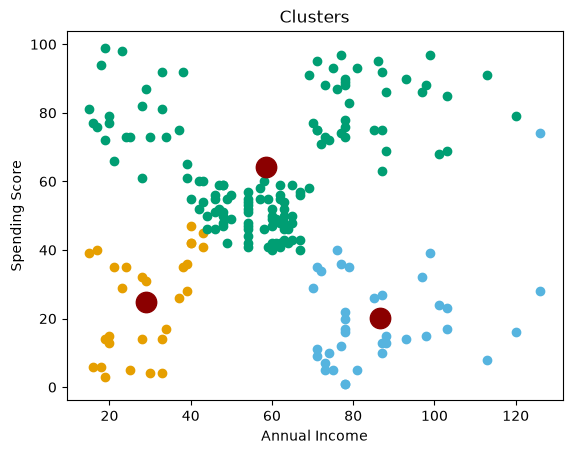

In [28]:
clustering = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init="auto",
    algorithm="lloyd"
)

clustered = clustering.fit(X=income_and_score)

centers: np.array = clustered.cluster_centers_
labels: np.array = clustered.labels_

income_and_score["Cluster_Label"] = labels

income_and_score


fig, ax = plt.subplots()
ax.set_xlabel("Annual Income")
ax.set_ylabel("Spending Score")
ax.set_title("Clusters")

colors: np.array = np.array([(230, 159, 0),   # Orange
                             (86, 180, 223),  # Light blue
                             (0, 158, 115),   # Green
                             (240, 228, 66),  # Yellow
                             (204, 121, 167)  # Pink
                             ]) / 255.0       # Colour blindness friendly

for i in range(len(income_and_score)):
    ax.scatter(x=income_and_score["Annual Income (k$)"].iloc[i],
               y=income_and_score["Spending Score (1-100)"].iloc[i],
               color=colors[income_and_score["Cluster_Label"].iloc[i]],
               label=f"Cluster {income_and_score["Cluster_Label"].iloc[i]}")

centroids = ax.scatter(x=centers[0:, 0],
                       y=centers[0:, 1],
                       c="DarkRed",
                       s=plt.rcParams['lines.markersize']**3,
                       label="Centroids")

plt.show()